In [1]:
#import os
#os.environ["SDL_VIDEODRIVER"] = "dummy"
from scripts.pygame_env import CustomEnv
import argparse
import pygame as pg
from scripts.DQN_modified_plus_simplified import DeepQNetwork
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from scripts.Boxer import Boxer
import csv
import os
import os.path
#from mpl_toolkits.mplot3d import Axes3D
from scripts import constant
import time

num_episodes = 8000
max_epLength = 200

def run_game_greedy():
    RL.step = 0
    for i in range(NUMBER_OF_AGENT):
        Boxer_list[i].step = 0

    Box_position_list_x =[]
    Box_position_list_y = []
    Box_heading_list = []

    Boxer_qmax_list = [[] for _ in range(NUMBER_OF_AGENT)]





    for episode in range(1):
        observation = env.reset(manual_set=manual_set)
        Box1 = env.object_boxes[0]

        episode_steps = 0

        episode_reward = []

        reach_goal_history = []
        reach_goal_trajectory = []
        rotation_list = []
        x_list = []
        y_list = []


        for i in range(NUMBER_OF_AGENT):
            episode_reward.append(0)

        while True:
            """fresh env"""
            env.render()
            #print("Box position vector is:", Box1.position_vector)

            '''Get q_max value for each boxer'''

            Boxer_qmax_value_list = []

            action_list=[]
            for i in range(NUMBER_OF_AGENT):
                Boxer_qmax_value_list.append(Boxer_list[i].get_qmax(observation[RL.Boxer_name[i]]))

            Box_position_list_x.append(Box1.position_vector.x)
            Box_position_list_y.append(Box1.position_vector.y)
            Box_heading_list.append(Box1.current_heading)

            for i in range(NUMBER_OF_AGENT):
                Boxer_qmax_list[i].append(Boxer_qmax_value_list[i])

            """RL choose action based on observation"""
            action = RL.choose_action_greedy(observation, epsilon_greedy=0)


            #print(action)
            for i in range(NUMBER_OF_AGENT):
                action_list.append(action[RL.Boxer_name[i]])
            #print(action_list)

            reach_goal_trajectory.append(action_list)

            Number_of_0 = action_list.count(0)  #region 1 one-hit
            Number_of_1 = action_list.count(1)  #region 2 two-hit
            Number_of_2 = action_list.count(2)  #region 3 three-hit
            Number_of_3 = action_list.count(3)  #region 4 four-hit
            Number_of_4 = action_list.count(4)  #region 5 five-hit
            Number_of_5 = action_list.count(5)  #region 6 six-hit
            Sum = Number_of_0 + Number_of_1 + Number_of_2 + Number_of_3 + Number_of_4 + Number_of_5
            rotation = Number_of_0 + Number_of_2 - Number_of_1 - Number_of_3
            #change_x = (self.three_hit + self.four_hit - self.one_hit - self.two_hit)
            #change_y = (self.five_hit - self.six_hit)
            change_x = Number_of_2 + Number_of_3 - Number_of_0 - Number_of_1
            change_y = Number_of_4 - Number_of_5
            #print(rotation)
            rotation_list.append(rotation)
            x_list.append(change_x)
            y_list.append(change_y)


            """Take action and get next observation and reward"""

            observation_, reward, done, _ = env.step(action, RL.Boxer_name)

            print("current heading: ", env.object_boxes[0].current_heading)

            for i in range(NUMBER_OF_AGENT):
                episode_reward[i] += reward[RL.Boxer_name[i]]

            """Swap observation"""
            observation = observation_

            episode_steps += 1

            RL.step += 1
            for i in range(NUMBER_OF_AGENT):
                Boxer_list[i].step += 1

            if done['Boxer1'] or episode_steps > max_epLength:
                #print('yes')
                #print(done['Boxer1'])
                if env.reach_goal == True:
                    reach_goal_history.append(1)
                else:

                    reach_goal_history.append(0)

            """break while loop when end of this episode or when episode is too many"""
            if done['Boxer1'] or episode_steps > max_epLength:
                #print('yes')
                break
        print("episode is :", episode)



    print('game is over')



pygame 2.5.1 (SDL 2.28.2, Python 3.10.1)
Hello from the pygame community. https://www.pygame.org/contribute.html


In [75]:
env = CustomEnv(random_initialization=False, n_agents=1)
observation = env.reset(manual_set=None)
pg.quit()

Fixed initial position
Fixed initial position


In [63]:
parser = argparse.ArgumentParser()
parser.add_argument('-number_agent', type=int, default=5,
                help='choose number of agents')
parser.add_argument('-random_seed', type=int, default=5,
                help='choose the random seed number')
parser.add_argument('-number_agent_trained_model', type=int, default=5,
                help='choose the number of agent of trained model')
parser.add_argument('-random_seed_trained_model', type=int, default=5,
                help='choose the random seed number associated with trained models')
args = parser.parse_args("")

NUMBER_OF_AGENT = args.number_agent
random_seed=args.random_seed
NUMBER_OF_AGENT_TRAINED_MODEL = args.number_agent_trained_model
random_seed_trained_model = args.random_seed_trained_model
np.random.seed(random_seed)
tf.random.set_seed(random_seed)

RL = DeepQNetwork(n_agents=5,
                  n_actions=env.action_space.n,
                  n_features=env.observation_space.shape[0],
                  load_model=False,
                  #path="./dqn",
                  path="./NUM_AGENT" +str(NUMBER_OF_AGENT).zfill(2) +"/" +
                       str(random_seed).zfill(4) +'/saved_model',
                  output_graph=True,
                  random_seed=random_seed,
                  n_agents_trained_model=NUMBER_OF_AGENT_TRAINED_MODEL,
                  random_seed_trained_model=random_seed_trained_model,
                  number_episode=num_episodes
                  )

In [76]:
observation

{'Boxer1': array([ 0.,  0.,  1.,  1.,  1.,  1.,  0.,  0., -1.])}

In [107]:
boxer = RL.Boxer[0]

count = {}
for _ in range(10000):
    action = boxer.choose_action(observation["Boxer1"])
    count[action] = count.get(action, 0) + 1
count

{1: 1601, 0: 1611, 2: 1687, 5: 1751, 4: 1700, 3: 1650}

Namespace(number_agent=5, random_seed=5, number_agent_trained_model=5, random_seed_trained_model=5)
number of agent is: 5
Fixed initial position
Manually setting initial Box position
loading exact 5 trained models
Manually setting initial Box position
current heading:  135.0
current heading:  135.0
current heading:  135.0
current heading:  135.0
current heading:  120.00000000000001
current heading:  114.99999999999999
current heading:  95.0
current heading:  75.00000000000001
Collision with patches
current heading:  65.00000000000001
episode is : 0
game is over
total time is: 0.7110223770141602 seconds


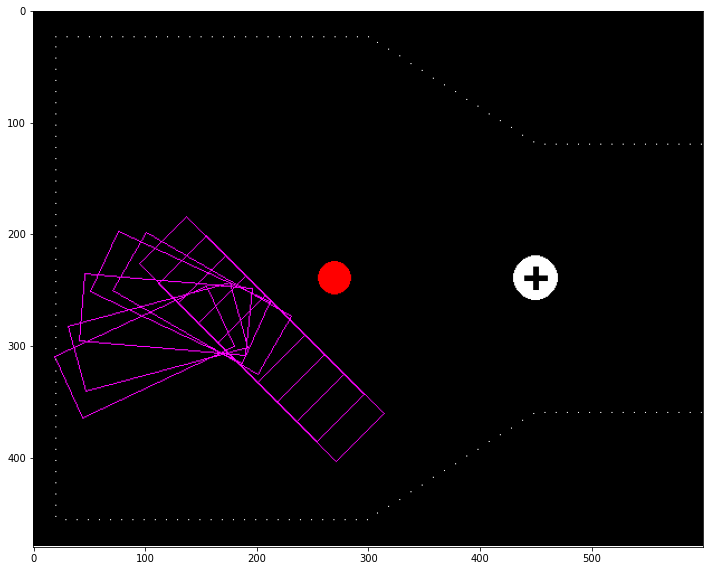

In [9]:
start = time.time()
loading_model = False
'''
random_seed is dumpy input as it is greedy algorithm, no random is involved
number_agent_trained_model and random_seed_trained_model is necessary for run_game_greedy
'''

parser = argparse.ArgumentParser()
parser.add_argument('-number_agent', type=int, default=5,
                help='choose number of agents')
parser.add_argument('-random_seed', type=int, default=5,
                help='choose the random seed number')
parser.add_argument('-number_agent_trained_model', type=int, default=5,
                help='choose the number of agent of trained model')
parser.add_argument('-random_seed_trained_model', type=int, default=5,
                help='choose the random seed number associated with trained models')
args = parser.parse_args("")

print('=' * 50)
print(args)
print('=' * 50)
NUMBER_OF_AGENT = args.number_agent
random_seed=args.random_seed
NUMBER_OF_AGENT_TRAINED_MODEL = args.number_agent_trained_model
random_seed_trained_model = args.random_seed_trained_model
np.random.seed(random_seed)
tf.random.set_seed(random_seed)

print("number of agent is:", NUMBER_OF_AGENT)
env = CustomEnv(random_initialization=False, n_agents=NUMBER_OF_AGENT)

##############################################################################
# manually set box initial position
# If fixed, box1 = Box(initial_x=120, initial_y=240, width=constant.box_width, height=constant.box_height)
manual_set = {
    "initial_x": 240,
    "initial_y": 330,
    "initial_heading": 135/180*np.pi
}
env.reset(manual_set=manual_set)
# print(env.object_boxes[0].current_heading)
env.object_boxes[0].determine_move()
env.object_boxes[0].determine_vertices()
##############################################################################

RL = DeepQNetwork(n_agents=NUMBER_OF_AGENT,
                  n_actions=env.action_space.n,
                  n_features=env.observation_space.shape[0],
                  load_model=loading_model,
                  #path="./dqn",
                  path="./NUM_AGENT" +str(NUMBER_OF_AGENT).zfill(2) +"/" +
                       str(random_seed).zfill(4) +'/saved_model',
                  output_graph=True,
                  random_seed=random_seed,
                  n_agents_trained_model=NUMBER_OF_AGENT_TRAINED_MODEL,
                  random_seed_trained_model=random_seed_trained_model,
                  number_episode=num_episodes
                  )
Boxer_list = []
for i in range(NUMBER_OF_AGENT):
    Boxer_list.append(RL.Boxer[i])

RL.loading_parameters(random_seed_trained_model, NUMBER_OF_AGENT_TRAINED_MODEL, random_seed)

run_game_greedy()
end = time.time()
print('total time is: {} seconds'.format(str(end-start)))

imgdata = pg.surfarray.array3d(env.screen)
plt.figure(figsize=[12, 15])
plt.ylim([480, 0])
plt.imshow(imgdata.transpose(1,0,2))
pg.quit()

In [111]:
single_push = {0: np.array([-5, 0, 5]),
               1: np.array([-5, 0, -5]),
               2: np.array([5, 0, 5]),
               3: np.array([5, 0, -5]),
               4: np.array([0, 5, 0]),
               5: np.array([0, -5, 0]),}

action_set = [(0, 0, 0)]
                       

In [116]:
def get_new_action_set(action_set):
    new_action_set = set()

    for s in action_set:
        for a in single_push:
            new = np.array(s) + single_push[a]
            new_action_set.add(tuple(new))
    return new_action_set

In [119]:
one = get_new_action_set(action_set)
len(one)

6

In [120]:
two = get_new_action_set(one)
len(two)

19

In [125]:
three = get_new_action_set(two)
len(three)

44

In [126]:
four = get_new_action_set(three)
len(four)

85

In [127]:
five = get_new_action_set(four)
len(five)

146

In [128]:
six = get_new_action_set(five)
len(six)

231

In [140]:
def check_base_move(action_set):
    print(f"(10, 0, 0) in action_set: {(10, 0, 0) in action_set}")
    print(f"(0, 10, 0) in action_set: {(0, 10, 0) in action_set}")
    print(f"(0, 0, 10) in action_set: {(0, 0, 10) in action_set}")

check_base_move(six)

(10, 0, 0) in action_set: True
(0, 10, 0) in action_set: True
(0, 0, 10) in action_set: True


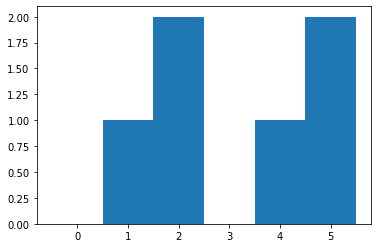

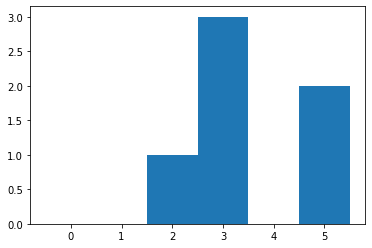

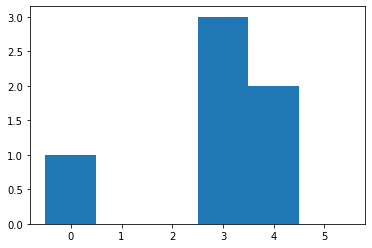

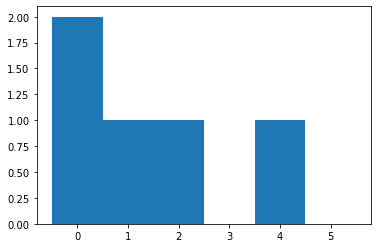

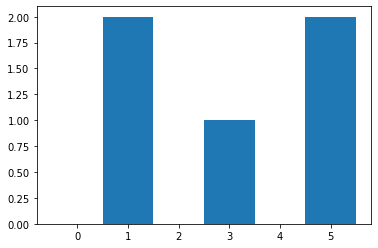

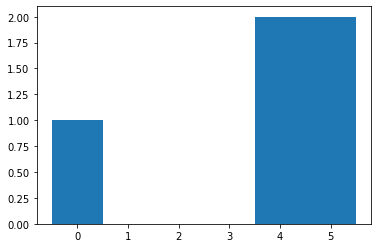

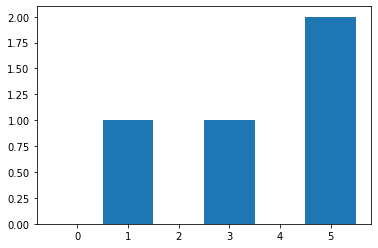

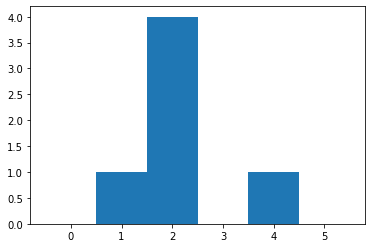

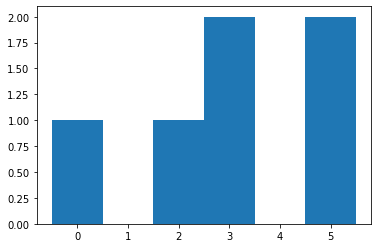

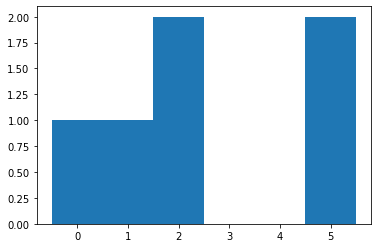

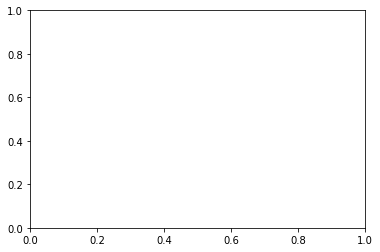

In [8]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure()

for i in range(10):
    count = np.random.randint(0, 7, size=6)
    plt.hist(count, bins=[i-0.5 for i in range(7)], range=(0, 7))
    plt.show()
    plt.cla()

In [12]:
action = {'Boxer1': 6, 'Boxer2': 6, 'Boxer3': 1}
list(action.values())

[6, 6, 1]